# Сравнение Ridge и Lasso на одном наборе данных

**Индивидуальное задание по курсу «Основы машинного обучения»**  
**Студент:** 32-Крутянский Роман

## Цель работы

Сравнить поведение двух видов регуляризации - **Ridge (L2)** и **Lasso (L1)** - на одном и том же наборе данных **California housing**. Нужно не просто обучить модели, а проверить:

- какая модель даёт лучшее качество на кросс-валидации и отложенном тесте;
- как регуляризация влияет на коэффициенты;
- в каких условиях Lasso действительно выполняет отбор признаков, а в каких его преимущество не проявляется.

## Сравниваемые модели

Линейная регрессия минимизирует сумму квадратов ошибок:

$$\hat{w} = \arg\min_w \|y - Xw\|_2^2.$$

**Ridge** добавляет L2-штраф:

$$\hat{w} = \arg\min_w \|y - Xw\|_2^2 + \alpha \|w\|_2^2.$$

**Lasso** добавляет L1-штраф:

$$\hat{w} = \arg\min_w \|y - Xw\|_2^2 + \alpha \|w\|_1.$$

L2-штраф плавно уменьшает все коэффициенты, но почти никогда не делает их точно нулевыми. L1-штраф может обнулять часть коэффициентов, поэтому Lasso одновременно является методом отбора признаков.

## План эксперимента

1. Загрузить California housing и выполнить первичный анализ.
2. Разделить данные на обучающую и тестовую части.
3. Для Ridge и Lasso подобрать `alpha` только по обучающей части с помощью кросс-валидации.
4. Сравнить модели по RMSE, MAE и R² на кросс-валидации и на отложенном тесте.
5. Исследовать коэффициенты: coefficient path, число ненулевых коэффициентов, сравнение при лучшем `alpha`.
6. Провести дополнительный контролируемый эксперимент: добавить к тем же данным шумовые признаки и проверить, обнуляет ли их Lasso.

## 1. Импорты и настройки

Фиксируем `random_state`, чтобы все разбиения и результаты воспроизводились.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.datasets import fetch_california_housing
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge, lasso_path
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5

FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

CV = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
ALPHAS_RAW = np.logspace(-4, 3, 60)
ALPHAS_NOISE = np.logspace(-4, 2, 40)

## 2. Загрузка данных

Используется встроенный набор `California housing` из `scikit-learn`: 20 640 объектов и 8 числовых признаков. Целевая переменная - медианная стоимость дома, выраженная в сотнях тысяч долларов.

Важная особенность: значения целевой переменной **обрезаны сверху** примерно на `5.00001`. Это ограничение данных, которое нужно учитывать при интерпретации ошибок.

In [2]:
data = fetch_california_housing(as_frame=True)
X = data.data.copy()
y = data.target.copy()
y.name = "MedHouseVal"
df = data.frame.copy()

print(f"Размер X: {X.shape}")
print(f"Размер y: {y.shape}")
print(f"Всего пропусков: {int(df.isna().sum().sum())}")
print(f"min(y) = {y.min():.5f}; max(y) = {y.max():.5f}")
print(f"Объектов со значением target == max: {int((y == y.max()).sum())}")

display(df.head())
display(df.describe().T.round(3))

Размер X: (20640, 8)
Размер y: (20640,)
Всего пропусков: 0
min(y) = 0.14999; max(y) = 5.00001
Объектов со значением target == max: 965


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


## 3. Первичный анализ данных

Посмотрим на распределение целевой переменной. Обратите внимание на резкий пик у верхней границы: часть наблюдений цензурирована.

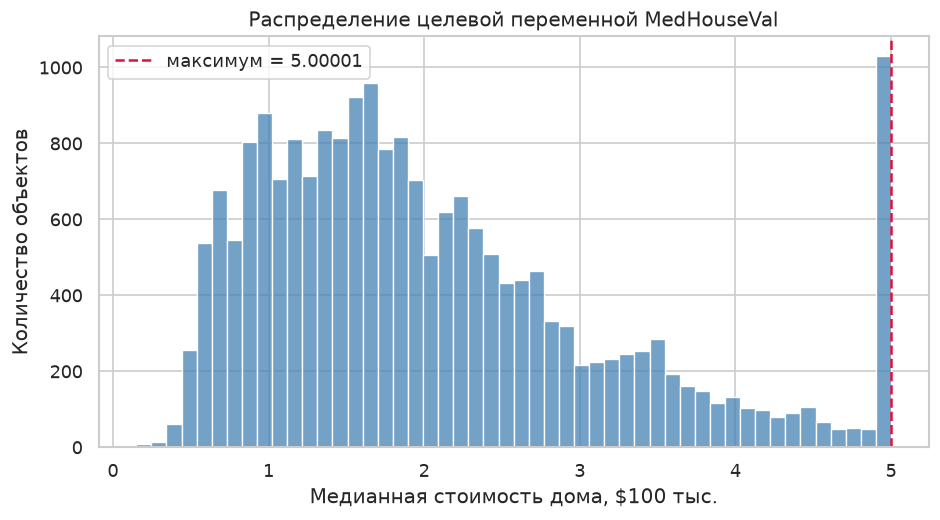

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(y, bins=50, ax=ax, color="steelblue")
ax.axvline(y.max(), color="crimson", ls="--", lw=1.5, label=f"максимум = {y.max():.5f}")
ax.set_title("Распределение целевой переменной MedHouseVal")
ax.set_xlabel("Медианная стоимость дома, $100 тыс.")
ax.set_ylabel("Количество объектов")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_target_distribution.png", bbox_inches="tight")
plt.show()

Корреляционная матрица показывает, какие признаки линейно связаны с целевой переменной. Наиболее заметна связь с `MedInc`.

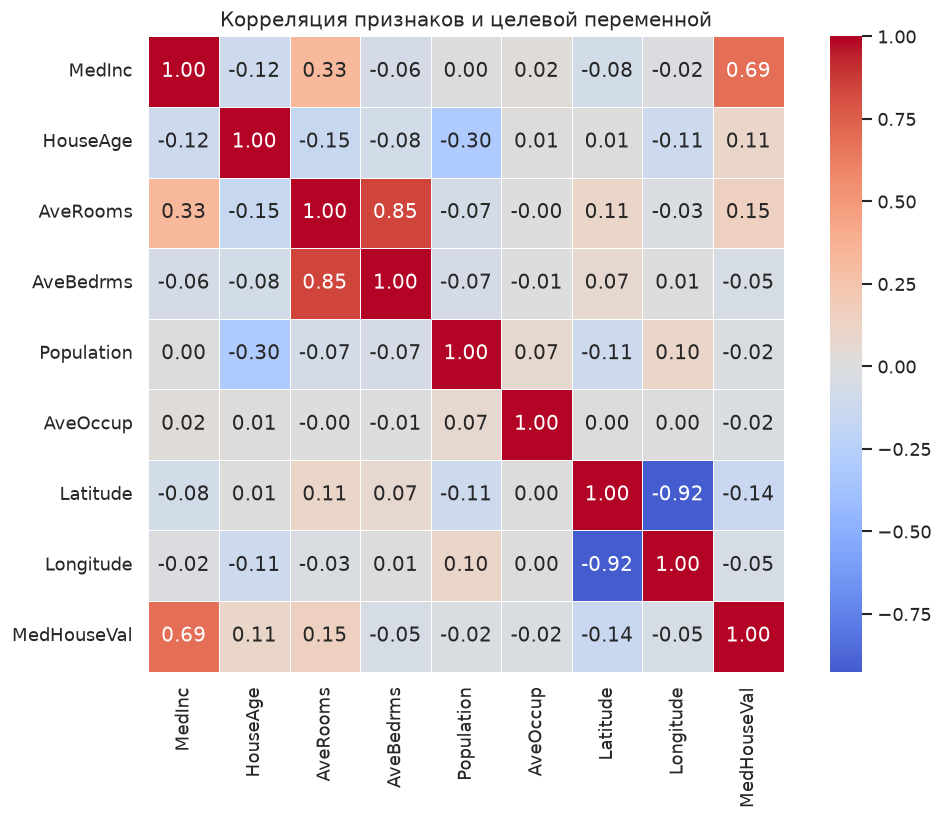

In [4]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Корреляция признаков и целевой переменной")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_correlation.png", bbox_inches="tight")
plt.show()

Признаки имеют разные масштабы: например, `Population` измеряется в тысячах, а `AveRooms` - в единицах. Для линейных моделей с регуляризацией это важно: штраф применяется к коэффициентам, поэтому без масштабирования Lasso и Ridge будут штрафовать признаки неравномерно. Поэтому далее используется `StandardScaler` **внутри Pipeline**.

In [5]:
display(X.describe().T[["mean", "std", "min", "max"]].round(3))

,mean,std,min,max
MedInc,3.871,1.900,0.500,15.000
HouseAge,28.639,12.586,1.000,52.000
AveRooms,5.429,2.474,0.846,141.909
AveBedrms,1.097,0.474,0.333,34.067
Population,1425.477,1132.462,3.000,35682.000
AveOccup,3.071,10.386,0.692,1243.333
Latitude,35.632,2.136,32.540,41.950
Longitude,-119.570,2.004,-124.350,-114.310


## 4. Разделение на обучающую и тестовую части

Разбиение выполняется **до** обучения любых преобразователей. Все параметры масштабирования и коэффициенты моделей настраиваются только на `X_train`, чтобы не было утечки информации из тестовой выборки.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка:  {X_test.shape[0]} объектов")

Обучающая выборка: 16512 объектов
Тестовая выборка:  4128 объектов


## 5. Методика, метрики и кросс-валидация

### Условия честного сравнения

Для Ridge и Lasso используются:

- одинаковое разбиение train/test;
- одинаковый `StandardScaler`;
- одинаковые фолды `KFold(5, shuffle=True, random_state=42)`;
- одинаковая сетка `alpha` внутри каждого эксперимента;
- выбор `alpha` только по обучающей части.

`alpha` - сила регуляризации. Чем больше `alpha`, тем сильнее штраф за большие коэффициенты. Слишком маленькое `alpha` почти не регулирует модель, слишком большое - чрезмерно упрощает её. Поэтому `alpha` подбирается по кросс-валидации. Лучшим считается `alpha` с минимальным CV RMSE.

### RMSE (Root Mean Squared Error)

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}.$$

RMSE измеряется в тех же единицах, что и target (сотни тысяч долларов). Чем меньше, тем лучше. Квадрат внутри формулы сильнее штрафует большие ошибки, поэтому RMSE чувствителен к крупным промахам. Это основная метрика в работе.

### MAE (Mean Absolute Error)

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|.$$

Средняя абсолютная ошибка в тех же единицах. Чем меньше, тем лучше. MAE меньше реагирует на отдельные большие ошибки, поэтому дополняет RMSE.

### R² (коэффициент детерминации)

$$R^2 = 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2}.$$

Показывает, какую долю дисперсии target объяснила модель. 1 - идеальное предсказание, 0 - модель не лучше, чем всегда предсказывать среднее, отрицательное значение - модель хуже среднего. Чем больше, тем лучше.

### Кросс-валидация и фолды

Чтобы не настраивать `alpha` по тесту, обучающая часть делится на `K` частей - **фолдов**. Модель обучается `K` раз: на `K-1` фолдах, а на оставшемся проверяется. Каждый объект ровно один раз попадает в валидацию. В работе `K=5`.

- **CV RMSE** - среднее RMSE по пяти фолдам.
- **±** - стандартное отклонение RMSE между фолдами. Оно показывает, насколько результат устойчив к составу данных.
- Если разница между моделями меньше этого разброса, говорить о существенном превосходстве нельзя.
- Ridge и Lasso проверяются на **одних и тех же фолдах**, поэтому можно сравнивать их RMSE на каждом фолде (попарное сравнение).

### Test RMSE

После выбора `alpha` модель обучается на всей обучающей части и один раз проверяется на отложенных 20% данных. Эти 20% не участвовали ни в обучении, ни в подборе `alpha`, поэтому test-метрики - честная оценка обобщения.

### Число ненулевых коэффициентов

В линейной модели коэффициент показывает вклад признака. Если коэффициент равен нулю, признак фактически не используется. Поэтому число ненулевых коэффициентов - это **сложность модели** и её «размер»:

- 8 из 8 - модель использует все признаки;
- 50 из 100 - модель использует 50 признаков, а 50 отбросила;
- меньше ненулевых коэффициентов -> проще интерпретировать модель, но это полезно только если качество не ухудшается.

Именно поэтому у Ridge в таблицах ниже 208 ненулевых коэффициентов, а у Lasso - 94: L1-штраф действительно обнуляет часть признаков, а L2-штраф только уменьшает их.

### Что значит «лучше»

«Лучше» зависит от критерия:

1. **Точность:** меньше RMSE/MAE, больше R².
2. **Разреженность:** меньше ненулевых коэффициентов при сопоставимом качестве.
3. **Устойчивость:** меньше разброс по фолдам и стабильное преимущество на всех фолдах.

На исходных 8 признаках точность моделей практически одинаковая. На данных с шумовыми признаками Lasso выигрывает и по точности, и по разреженности, но выигрыш по точности небольшой. Основной практический выигрыш Lasso - более простая и интерпретируемая модель.

In [7]:
def evaluate_model(name, model, alphas=None, X_tr=None, y_tr=None, X_te=None, y_te=None):
    """Обучает модель, подбирает alpha по CV и возвращает метрики и коэффициенты."""
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model),
    ])

    if alphas is not None:
        search = GridSearchCV(
            pipeline,
            {"model__alpha": alphas},
            cv=CV,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
        search.fit(X_tr, y_tr)
        best_model = search.best_estimator_
        best_alpha = float(search.best_params_["model__alpha"])
    else:
        search = None
        best_model = clone(pipeline).fit(X_tr, y_tr)
        best_alpha = np.nan

    cv_res = cross_validate(
        best_model,
        X_tr,
        y_tr,
        cv=CV,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        n_jobs=-1,
    )

    y_pred = best_model.predict(X_te)
    coef = best_model.named_steps["model"].coef_

    return {
        "name": name,
        "alpha": best_alpha,
        "cv_rmse_mean": -cv_res["test_rmse"].mean(),
        "cv_rmse_std": cv_res["test_rmse"].std(),
        "cv_mae_mean": -cv_res["test_mae"].mean(),
        "cv_r2_mean": cv_res["test_r2"].mean(),
        "test_rmse": root_mean_squared_error(y_te, y_pred),
        "test_mae": mean_absolute_error(y_te, y_pred),
        "test_r2": r2_score(y_te, y_pred),
        "nonzero": int(np.sum(np.abs(coef) > 1e-8)),
        "l1": float(np.linalg.norm(coef, 1)),
        "l2": float(np.linalg.norm(coef, 2)),
        "fold_rmse": -cv_res["test_rmse"],
        "fold_mae": -cv_res["test_mae"],
        "fold_r2": cv_res["test_r2"],
        "model": best_model,
        "search": search,
        "coef": coef,
    }


def results_to_frame(results):
    return pd.DataFrame([
        {
            "model": r["name"],
            "best_alpha": r["alpha"],
            "cv_rmse_mean": r["cv_rmse_mean"],
            "cv_rmse_std": r["cv_rmse_std"],
            "cv_mae_mean": r["cv_mae_mean"],
            "cv_r2_mean": r["cv_r2_mean"],
            "test_rmse": r["test_rmse"],
            "test_mae": r["test_mae"],
            "test_r2": r["test_r2"],
            "nonzero_coef": r["nonzero"],
            "l1_norm": r["l1"],
            "l2_norm": r["l2"],
        }
        for r in results
    ])


def show_results(df):
    shown = df.copy()
    shown["best_alpha"] = shown["best_alpha"].map(
        lambda a: "-" if pd.isna(a) else f"{a:.3g}"
    )
    display(shown.set_index("model").round(4))


def show_fold_comparison(results, name_a, name_b):
    a = next(r for r in results if r["name"] == name_a)
    b = next(r for r in results if r["name"] == name_b)
    fold_df = pd.DataFrame({
        "fold": np.arange(1, N_SPLITS + 1),
        f"{name_a}_rmse": a["fold_rmse"],
        f"{name_b}_rmse": b["fold_rmse"],
        "diff": a["fold_rmse"] - b["fold_rmse"],
    })
    display(fold_df.round(4).set_index("fold"))
    print(
        f"Средняя разница RMSE ({name_a} - {name_b}): "
        f"{fold_df['diff'].mean():.4f} ± {fold_df['diff'].std():.4f}"
    )
    return fold_df


def plot_cv_curves(results, save_path, title):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for r in results:
        if r["search"] is None:
            continue
        cvres = r["search"].cv_results_
        alphas = np.asarray(cvres["param_model__alpha"], dtype=float)
        mean = -np.asarray(cvres["mean_test_score"], dtype=float)
        std = np.asarray(cvres["std_test_score"], dtype=float)
        line, = ax.plot(alphas, mean, label=f'{r["name"]}')
        ax.fill_between(alphas, mean - std, mean + std, alpha=0.15, color=line.get_color())
        ax.axvline(r["alpha"], color=line.get_color(), ls=":", lw=1.2)
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("CV RMSE")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()


def fit_coefficient_path(X_data, y_data, alphas, model_factory):
    scaler = StandardScaler().fit(X_data)
    X_scaled = scaler.transform(X_data)
    coefs = []
    for alpha in alphas:
        model = model_factory(alpha)
        model.fit(X_scaled, y_data)
        coefs.append(model.coef_)
    return np.asarray(coefs)


def fit_lasso_path(X_data, y_data, alphas):
    """Быстрый расчёт Lasso path с warm start через lasso_path."""
    scaler = StandardScaler().fit(X_data)
    X_scaled = scaler.transform(X_data)
    alphas_out, coefs, _ = lasso_path(
        X_scaled,
        y_data,
        alphas=alphas,
        max_iter=100_000,
        tol=1e-3,
        selection="random",
        random_state=RANDOM_STATE,
    )
    order = np.argsort(alphas_out)
    return np.asarray(coefs).T[order]


def plot_paths_pair(alphas, coefs_a, coefs_b, feature_names, features,
                    alpha_a, alpha_b, title_a, title_b, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    colors = plt.cm.tab10(np.linspace(0, 1, len(features)))

    for ax, coefs, best_alpha, title in [
        (axes[0], coefs_a, alpha_a, title_a),
        (axes[1], coefs_b, alpha_b, title_b),
    ]:
        for color, feat in zip(colors, features):
            idx = feature_names.index(feat)
            ax.plot(np.log10(alphas), coefs[:, idx], color=color, lw=1.6, label=feat)
        ax.axvline(np.log10(best_alpha), color="black", ls="--", lw=1.1)
        ax.set_title(title)
        ax.set_xlabel("log10(alpha)")

    axes[0].set_ylabel("Коэффициент")
    axes[1].legend(fontsize=8, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()


def plot_sparsity(alphas, coefs_ridge, coefs_lasso, save_path, title):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(np.log10(alphas), (np.abs(coefs_ridge) > 1e-8).sum(axis=1), label="Ridge", lw=2)
    ax.plot(np.log10(alphas), (np.abs(coefs_lasso) > 1e-8).sum(axis=1), label="Lasso", lw=2)
    ax.set_xlabel("log10(alpha)")
    ax.set_ylabel("Число ненулевых коэффициентов")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()

## 6. Основной эксперимент: исходные 8 признаков

Сравниваем три модели:

- `OLS` - обычная линейная регрессия без регуляризации (baseline);
- `Ridge` - L2-регуляризация;
- `Lasso` - L1-регуляризация.

Для Ridge и Lasso перебирается `alpha` от `1e-4` до `1e3` по логарифмической сетке.

In [8]:
raw_results = [
    evaluate_model("OLS", LinearRegression(), alphas=None),
    evaluate_model("Ridge", Ridge(), alphas=ALPHAS_RAW),
    evaluate_model(
        "Lasso",
        Lasso(
            max_iter=100_000,
            tol=1e-3,
            selection="random",
            random_state=RANDOM_STATE,
        ),
        alphas=ALPHAS_RAW,
    ),
]

raw_df = results_to_frame(raw_results)
show_results(raw_df)
raw_df.to_csv(RESULTS_DIR / "raw_metrics.csv", index=False)

,best_alpha,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean,test_rmse,test_mae,test_r2,nonzero_coef,l1_norm,l2_norm
model,,,,,,,,,,,
OLS,-,0.7205,0.0139,0.5291,0.6115,0.7456,0.5332,0.5758,8,3.4205,1.5842
Ridge,2.45,0.7205,0.0139,0.5290,0.6115,0.7455,0.5332,0.5759,8,3.4156,1.5818
Lasso,0.000515,0.7205,0.0139,0.5291,0.6115,0.7451,0.5332,0.5763,8,3.3917,1.5732


### Зависимость CV RMSE от `alpha`

Вертикальные пунктирные линии соответствуют выбранному по кросс-валидации значению `alpha`.

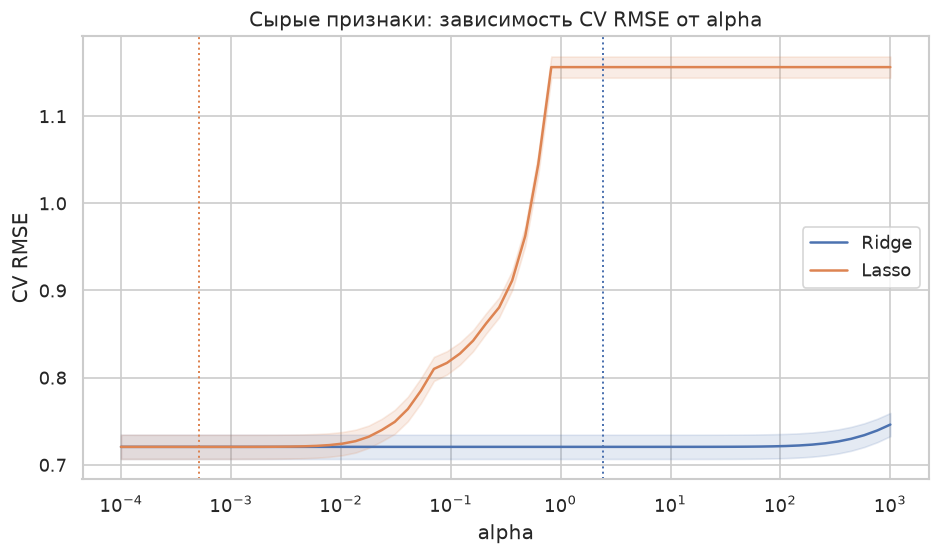

In [9]:
plot_cv_curves(
    raw_results,
    FIG_DIR / "03_cv_curves_raw.png",
    "Сырые признаки: зависимость CV RMSE от alpha",
)

### Coefficient path: как меняются коэффициенты при росте `alpha`

Слева - Ridge, справа - Lasso. При увеличении штрафа Ridge плавно уменьшает все коэффициенты. Lasso обнуляет часть коэффициентов, начиная с менее важных признаков.

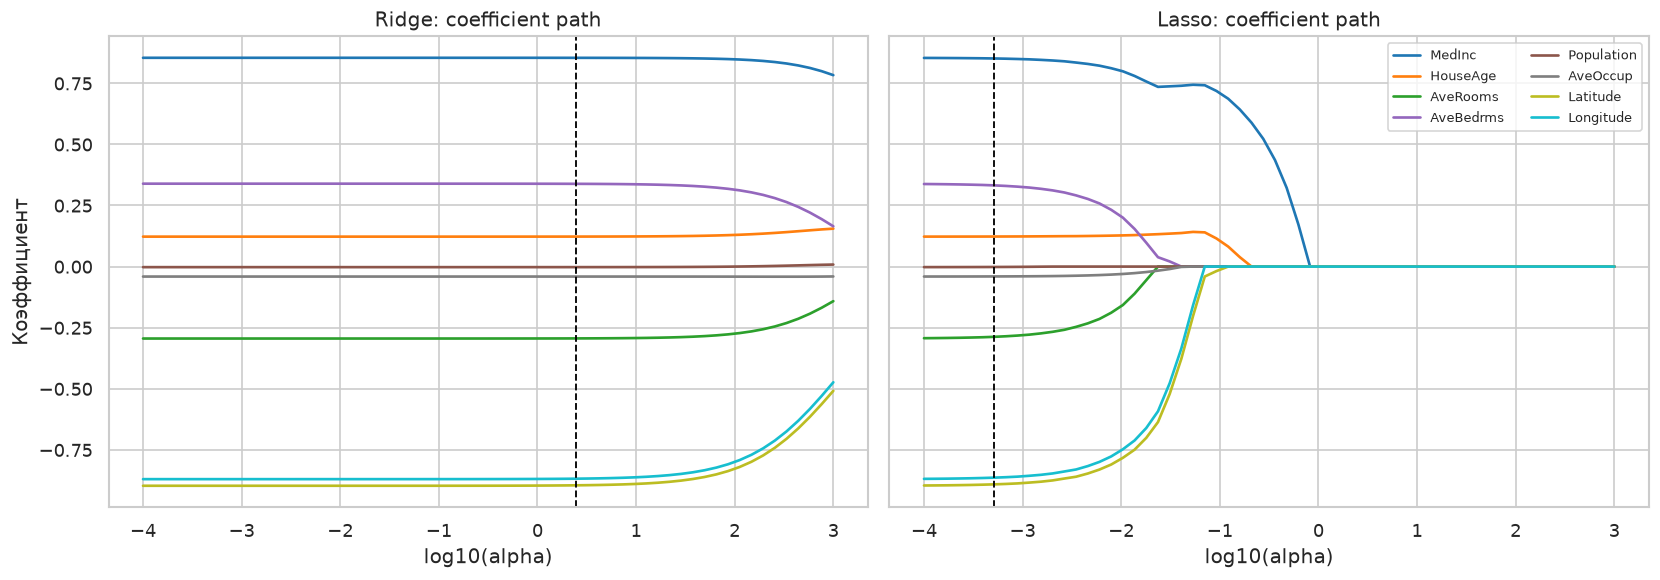

In [10]:
ridge_raw = next(r for r in raw_results if r["name"] == "Ridge")
lasso_raw = next(r for r in raw_results if r["name"] == "Lasso")

coefs_ridge_raw = fit_coefficient_path(
    X_train,
    y_train,
    ALPHAS_RAW,
    lambda a: Ridge(alpha=a),
)
coefs_lasso_raw = fit_lasso_path(X_train, y_train, ALPHAS_RAW)

plot_paths_pair(
    ALPHAS_RAW,
    coefs_ridge_raw,
    coefs_lasso_raw,
    feature_names=list(X.columns),
    features=list(X.columns),
    alpha_a=ridge_raw["alpha"],
    alpha_b=lasso_raw["alpha"],
    title_a="Ridge: coefficient path",
    title_b="Lasso: coefficient path",
    save_path=FIG_DIR / "04_coef_paths_raw.png",
)

### Число ненулевых коэффициентов

График показывает, как меняется разреженность решения при увеличении `alpha`. Это ключевое отличие L1 от L2.

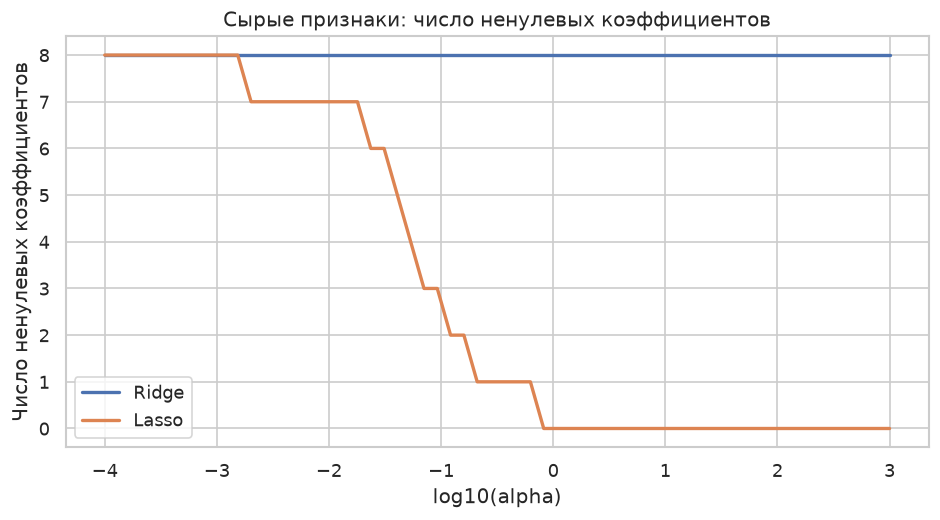

In [11]:
plot_sparsity(
    ALPHAS_RAW,
    coefs_ridge_raw,
    coefs_lasso_raw,
    FIG_DIR / "05_sparsity_raw.png",
    "Сырые признаки: число ненулевых коэффициентов",
)

### Коэффициенты при лучшем `alpha`

Сравним коэффициенты Ridge и Lasso, обученные на всей обучающей выборке с лучшими значениями `alpha`. Так как признаки стандартизованы, коэффициенты можно сравнивать по модулю.

,Ridge,Lasso,abs_diff
MedInc,0.8542,0.8518,0.0024
HouseAge,0.1227,0.1230,0.0003
AveRooms,-0.2939,-0.2879,0.0060
AveBedrms,0.3386,0.3327,0.0060
Population,-0.0022,-0.0017,0.0006
AveOccup,-0.0408,-0.0404,0.0005
Latitude,-0.8951,-0.8909,0.0042
Longitude,-0.8680,-0.8634,0.0045


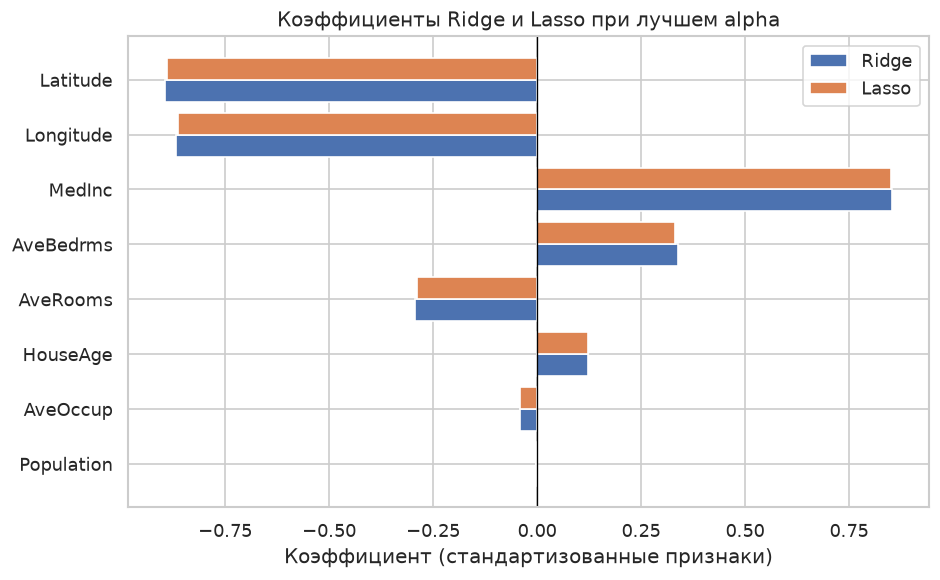

In [12]:
coef_df_raw = pd.DataFrame(
    {
        "Ridge": ridge_raw["coef"],
        "Lasso": lasso_raw["coef"],
    },
    index=X.columns,
)
coef_df_raw["abs_diff"] = (coef_df_raw["Ridge"] - coef_df_raw["Lasso"]).abs()

display(coef_df_raw.round(4))
coef_df_raw.to_csv(RESULTS_DIR / "coefficients_raw.csv")

order = coef_df_raw[["Ridge", "Lasso"]].abs().max(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(8, 5))
ypos = np.arange(len(order))
ax.barh(ypos - 0.2, coef_df_raw.loc[order, "Ridge"], height=0.4, label="Ridge")
ax.barh(ypos + 0.2, coef_df_raw.loc[order, "Lasso"], height=0.4, label="Lasso")
ax.set_yticks(ypos)
ax.set_yticklabels(order)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Коэффициент (стандартизованные признаки)")
ax.set_title("Коэффициенты Ridge и Lasso при лучшем alpha")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "06_coef_comparison_raw.png", bbox_inches="tight")
plt.show()

### Попарное сравнение по фолдам

Фолды одинаковые, поэтому можно посмотреть разницу RMSE на каждом фолде. Это устойчивее, чем сравнение одного среднего значения.

In [13]:
fold_raw = show_fold_comparison(raw_results, "Ridge", "Lasso")
fold_raw.to_csv(RESULTS_DIR / "fold_comparison_raw.csv", index=False)

,Ridge_rmse,Lasso_rmse,diff
fold,,,
1,0.7339,0.7339,0.0000
2,0.7251,0.7250,0.0002
3,0.6973,0.6973,-0.0000
4,0.7334,0.7334,-0.0001
5,0.7128,0.7129,-0.0000


Средняя разница RMSE (Ridge - Lasso): 0.0000 ± 0.0001


### Промежуточный вывод по сырым признакам

На исходном наборе из 8 признаков Ridge и Lasso дают практически одинаковое качество. Lasso при выбранном `alpha` **не обнуляет коэффициенты**: все восемь признаков остаются ненулевыми. Это ожидаемо:

- признаков мало, и почти все они несут информацию о цене;
- объём выборки большой, поэтому даже слабая регуляризация почти не нужна;
- между признаками есть корреляции, но Lasso всё равно сохраняет их, если они полезны для прогноза.

Таким образом, на этом этапе L1-преимущество в виде отбора признаков не проявляется. Чтобы проверить, работает ли механизм Lasso, нужен контролируемый эксперимент с заведомо лишними признаками.

## 7. Контролируемый эксперимент: те же данные + шумовые признаки

К исходным 8 признакам добавляются **200 независимых стандартных нормальных шумовых признаков**. Они не связаны с целевой переменной. Разбиение train/test и все реальные объекты остаются теми же.

Число шумовых признаков специально сделано большим, чтобы эффект отбора был заметнее. Это контролируемый стресс-тест, а не утверждение о типичном реальном датасете.

Если Lasso действительно выполняет отбор, он должен обнулить большую часть шумовых коэффициентов, тогда как Ridge будет вынужден оставить их ненулевыми. Это проверка механизма L1-регуляризации на том же наборе данных.

In [14]:
N_NOISE = 200
rng = np.random.default_rng(RANDOM_STATE)

noise = pd.DataFrame(
    rng.normal(size=(len(X), N_NOISE)),
    columns=[f"noise_{i:02d}" for i in range(N_NOISE)],
    index=X.index,
)

X_aug = pd.concat([X, noise], axis=1)

X_train_aug, X_test_aug, y_train_aug, y_test_aug = train_test_split(
    X_aug,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

assert np.allclose(y_train_aug, y_train)
assert np.allclose(y_test_aug, y_test)

print(f"Размер расширенного X: {X_aug.shape}")
print(f"Реальных признаков: {X.shape[1]}, шумовых: {noise.shape[1]}")
print(f"Обучающая выборка: {X_train_aug.shape[0]}, тестовая: {X_test_aug.shape[0]}")

Размер расширенного X: (20640, 208)
Реальных признаков: 8, шумовых: 200
Обучающая выборка: 16512, тестовая: 4128


Обучаем те же три модели на расширенном наборе. Сетка `alpha` для Ridge и Lasso снова одинаковая.

In [15]:
noise_results = [
    evaluate_model(
        "OLS",
        LinearRegression(),
        alphas=None,
        X_tr=X_train_aug,
        y_tr=y_train_aug,
        X_te=X_test_aug,
        y_te=y_test_aug,
    ),
    evaluate_model(
        "Ridge",
        Ridge(),
        alphas=ALPHAS_NOISE,
        X_tr=X_train_aug,
        y_tr=y_train_aug,
        X_te=X_test_aug,
        y_te=y_test_aug,
    ),
    evaluate_model(
        "Lasso",
        Lasso(
            max_iter=100_000,
            tol=1e-3,
            selection="random",
            random_state=RANDOM_STATE,
        ),
        alphas=ALPHAS_NOISE,
        X_tr=X_train_aug,
        y_tr=y_train_aug,
        X_te=X_test_aug,
        y_te=y_test_aug,
    ),
]

noise_df = results_to_frame(noise_results)
show_results(noise_df)
noise_df.to_csv(RESULTS_DIR / "noise_metrics.csv", index=False)

,best_alpha,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean,test_rmse,test_mae,test_r2,nonzero_coef,l1_norm,l2_norm
model,,,,,,,,,,,
OLS,-,0.7251,0.0139,0.5332,0.6065,0.7503,0.5382,0.5705,208,4.3422,1.5821
Ridge,8.38,0.7251,0.0139,0.5332,0.6065,0.7501,0.5381,0.5707,208,4.3256,1.5740
Lasso,0.00492,0.7221,0.0136,0.5306,0.6097,0.7433,0.5346,0.5784,94,3.4181,1.4829


### Насколько выигрыш Lasso велик?

Абсолютная разница в RMSE может выглядеть маленькой. Посчитаем относительное улучшение и сравним сложность моделей, чтобы понять практический масштаб различия.

In [16]:
ridge_noise_row = next(r for r in noise_results if r["name"] == "Ridge")
lasso_noise_row = next(r for r in noise_results if r["name"] == "Lasso")

rel_rmse = 100 * (
    ridge_noise_row["test_rmse"] - lasso_noise_row["test_rmse"]
) / ridge_noise_row["test_rmse"]
rel_mae = 100 * (
    ridge_noise_row["test_mae"] - lasso_noise_row["test_mae"]
) / ridge_noise_row["test_mae"]

print(f"Test RMSE Ridge: {ridge_noise_row['test_rmse']:.4f}")
print(f"Test RMSE Lasso: {lasso_noise_row['test_rmse']:.4f}")
print(f"Относительное улучшение RMSE у Lasso: {rel_rmse:.2f}%")
print(f"Относительное улучшение MAE у Lasso:  {rel_mae:.2f}%")
print(f"Ненулевых коэффициентов: Ridge = {ridge_noise_row['nonzero']}, Lasso = {lasso_noise_row['nonzero']}")

Test RMSE Ridge: 0.7501
Test RMSE Lasso: 0.7433
Относительное улучшение RMSE у Lasso: 0.90%
Относительное улучшение MAE у Lasso:  0.66%
Ненулевых коэффициентов: Ridge = 208, Lasso = 94


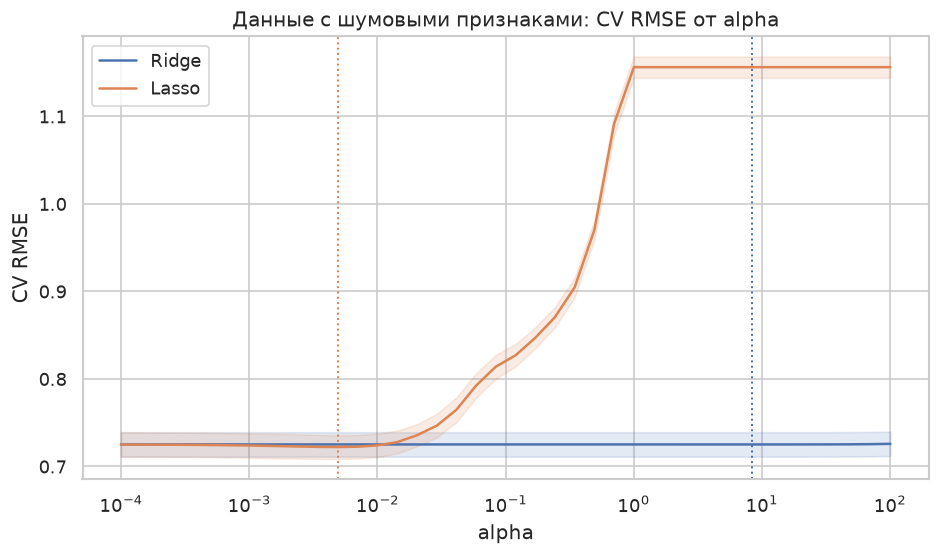

In [17]:
plot_cv_curves(
    noise_results,
    FIG_DIR / "07_cv_curves_noise.png",
    "Данные с шумовыми признаками: CV RMSE от alpha",
)

### Какие признаки оставил Lasso?

Сравним коэффициенты Ridge и Lasso. Звёздочкой отмечены шумовые признаки. Ожидается, что Ridge оставит ненулевыми все 200 шумовых коэффициентов, а Lasso обнулит значительную их часть.

,Ridge,Lasso
Реальные признаки (8),8,7
Шумовые признаки (200),200,87


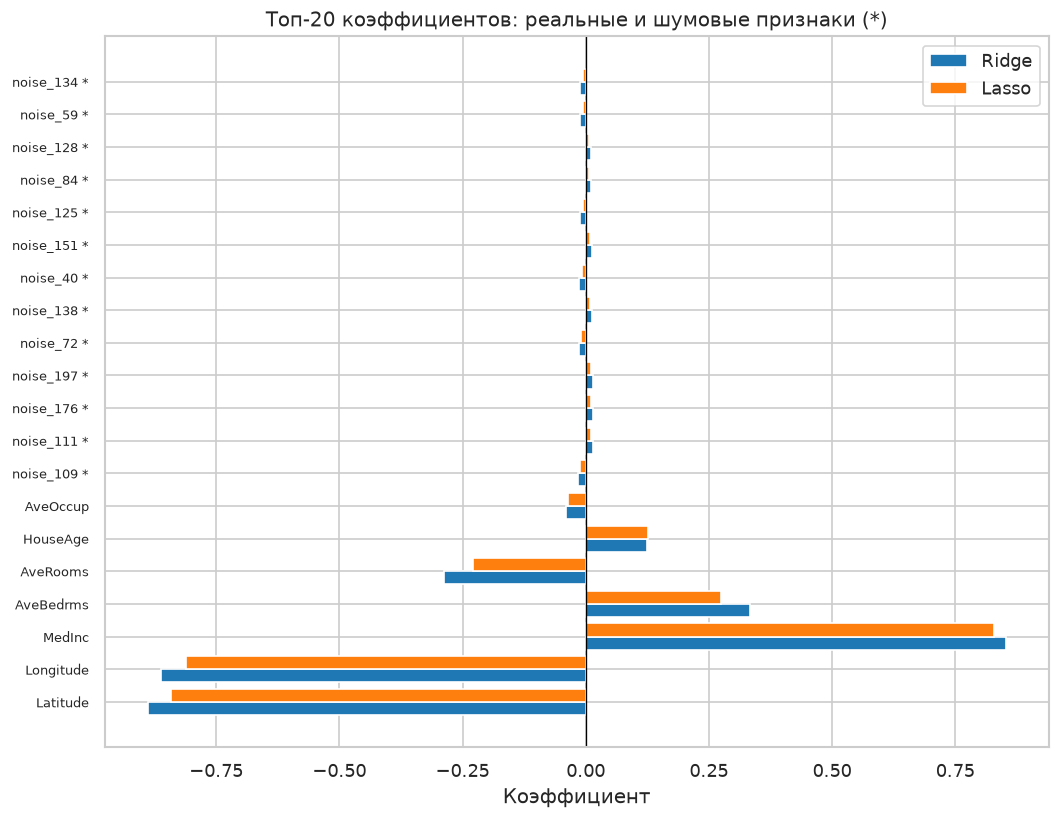

In [18]:
ridge_noise = next(r for r in noise_results if r["name"] == "Ridge")
lasso_noise = next(r for r in noise_results if r["name"] == "Lasso")

feature_names_aug = list(X_aug.columns)
coef_df_noise = pd.DataFrame(
    {
        "Ridge": ridge_noise["coef"],
        "Lasso": lasso_noise["coef"],
    },
    index=feature_names_aug,
)
coef_df_noise["type"] = [
    "real" if name in X.columns else "noise" for name in feature_names_aug
]

nonzero_summary = pd.DataFrame(
    {
        "Ridge": [
            int((coef_df_noise.loc[X.columns, "Ridge"].abs() > 1e-8).sum()),
            int((coef_df_noise.loc[noise.columns, "Ridge"].abs() > 1e-8).sum()),
        ],
        "Lasso": [
            int((coef_df_noise.loc[X.columns, "Lasso"].abs() > 1e-8).sum()),
            int((coef_df_noise.loc[noise.columns, "Lasso"].abs() > 1e-8).sum()),
        ],
    },
    index=["Реальные признаки (8)", "Шумовые признаки (200)"],
)
display(nonzero_summary)
nonzero_summary.to_csv(RESULTS_DIR / "nonzero_counts_noise.csv")
coef_df_noise.to_csv(RESULTS_DIR / "coefficients_noise.csv")

top = (
    coef_df_noise.assign(
        maxabs=coef_df_noise[["Ridge", "Lasso"]].abs().max(axis=1)
    )
    .sort_values("maxabs", ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(9, 7))
ypos = np.arange(len(top))
ax.barh(ypos - 0.2, top["Ridge"], height=0.4, color="tab:blue", label="Ridge")
ax.barh(ypos + 0.2, top["Lasso"], height=0.4, color="tab:orange", label="Lasso")
labels = [
    f"{name} *" if kind == "noise" else name
    for name, kind in zip(top.index, top["type"])
]
ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Коэффициент")
ax.set_title("Топ-20 коэффициентов: реальные и шумовые признаки (*)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "08_coef_comparison_noise.png", bbox_inches="tight")
plt.show()

### Разреженность на расширенном наборе

Слева - общее число ненулевых коэффициентов. Справа - отдельно для Lasso: сколько ненулевых реальных и шумовых признаков остаётся при разных `alpha`.

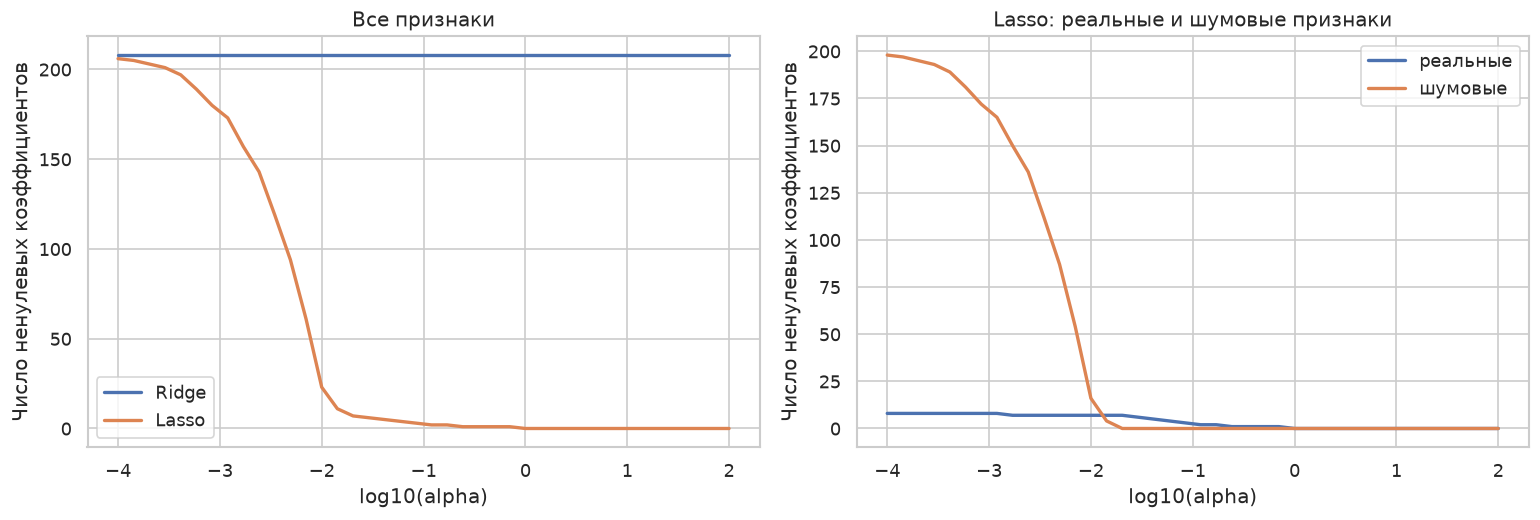

In [19]:
coefs_ridge_noise = fit_coefficient_path(
    X_train_aug,
    y_train_aug,
    ALPHAS_NOISE,
    lambda a: Ridge(alpha=a),
)
coefs_lasso_noise = fit_lasso_path(X_train_aug, y_train_aug, ALPHAS_NOISE)

real_idx = [feature_names_aug.index(name) for name in X.columns]
noise_idx = [feature_names_aug.index(name) for name in noise.columns]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(np.log10(ALPHAS_NOISE), (np.abs(coefs_ridge_noise) > 1e-8).sum(axis=1), label="Ridge", lw=2)
axes[0].plot(np.log10(ALPHAS_NOISE), (np.abs(coefs_lasso_noise) > 1e-8).sum(axis=1), label="Lasso", lw=2)
axes[0].set_xlabel("log10(alpha)")
axes[0].set_ylabel("Число ненулевых коэффициентов")
axes[0].set_title("Все признаки")
axes[0].legend()

axes[1].plot(np.log10(ALPHAS_NOISE), (np.abs(coefs_lasso_noise[:, real_idx]) > 1e-8).sum(axis=1), label="реальные", lw=2)
axes[1].plot(np.log10(ALPHAS_NOISE), (np.abs(coefs_lasso_noise[:, noise_idx]) > 1e-8).sum(axis=1), label="шумовые", lw=2)
axes[1].set_xlabel("log10(alpha)")
axes[1].set_ylabel("Число ненулевых коэффициентов")
axes[1].set_title("Lasso: реальные и шумовые признаки")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "09_sparsity_noise.png", bbox_inches="tight")
plt.show()

### Попарное сравнение по фолдам на расширенном наборе

In [20]:
fold_noise = show_fold_comparison(noise_results, "Ridge", "Lasso")
fold_noise.to_csv(RESULTS_DIR / "fold_comparison_noise.csv", index=False)

,Ridge_rmse,Lasso_rmse,diff
fold,,,
1,0.7378,0.7347,0.0031
2,0.7312,0.7262,0.0050
3,0.7014,0.6993,0.0021
4,0.7375,0.7355,0.0020
5,0.7175,0.7148,0.0027


Средняя разница RMSE (Ridge - Lasso): 0.0030 ± 0.0012


### Вывод по контролируемому эксперименту

При добавлении 200 шумовых признаков картина меняется:

- Ridge оставляет ненулевыми **все** шумовые коэффициенты, лишь немного уменьшая их по модулю;
- Lasso обнуляет большую часть шумовых коэффициентов и сохраняет почти все реальные признаки;
- Lasso выигрывает по test RMSE, MAE и R², причём выигрывает на всех пяти фолдах.

Но важно правильно оценить масштаб: по точности выигрыш составляет около одного процента, а по числу используемых признаков - в несколько раз. То есть Lasso выигрывает прежде всего за счёт разреженности и интерпретируемости, а не за счёт радикального улучшения прогноза.

## 8. Итоговые выводы: что лучше?

### Сначала о метриках

- RMSE и MAE измеряются в сотнях тысяч долларов: чем меньше, тем лучше.
- R² показывает долю объяснённой дисперсии: чем ближе к 1, тем лучше.
- CV RMSE - среднее по фолдам, ± - разброс между фолдами.
- Число ненулевых коэффициентов показывает, сколько признаков реально использует модель.

### Сравнение по критериям

| Критерий | Сырые 8 признаков | 8 + 200 шумовых |
|---|---|---|
| Точность (RMSE/MAE/R²) | практически ничья | Lasso немного лучше |
| Разреженность | ничья: 8 из 8 | Lasso заметно лучше: использует меньшую часть признаков |
| Устойчивость | разница в пределах разброса | Lasso лучше на всех 5 фолдах |
| Интерпретируемость | одинаковая | Lasso проще |
| Когда выбирать | Ridge для стабильности, Lasso если нужна разреженность | Lasso |

### Ответ на вопрос «что лучше?»

- На исходных 8 признаках **нет практического победителя по точности**. Если нужна простая устойчивая модель - берите Ridge; если нужна разреженность - Lasso, но на этих данных он её не даёт.
- При большом числе неинформативных признаков **Lasso лучше**: он точнее и, главное, отбрасывает лишние признаки. Но выигрыш по RMSE небольшой (порядка одного процента), поэтому если нужен именно прогноз, разница может быть несущественной.
- **Универсального победителя нет.** Ridge лучше при коррелирующих полезных признаках и когда важна стабильность. Lasso лучше при большом числе неинформативных признаков и когда важна интерпретируемость. ElasticNet - компромисс.

### Почему разница по RMSE такая маленькая?

California housing - не высокоразмерная задача: 8 исходных признаков и 20 640 объектов. Линейная модель уже неплохо описывает зависимость, поэтому регуляризация мало меняет ошибку. Lasso показывает преимущество в отборе признаков, но не может дать большой прирост точности там, где и так мало шума. Это ожидаемый результат, а не ошибка эксперимента.

### Ограничения работы

- Использован один набор данных и одно разбиение train/test; результаты могут зависеть от разбиения.
- Целевая переменная обрезана сверху, что ограничивает качество на дорогих домах.
- `alpha` выбирался на тех же фолдах, на которых затем измерялось CV-качество; для более строгой оценки следовало бы использовать вложенную кросс-валидацию.
- Шумовые признаки искусственные и независимые; в реальных данных лишние признаки могут быть коррелированы с полезными.
- Сравнивались только линейные модели; нелинейные зависимости (например, по географическим координатам) остаются за рамками работы.

In [21]:
print("Сохранённые графики:")
for path in sorted(FIG_DIR.glob("*.png")):
    print(" -", path)

print("\nСохранённые таблицы:")
for path in sorted(RESULTS_DIR.glob("*.csv")):
    print(" -", path)

Сохранённые графики:
 - figures/01_target_distribution.png
 - figures/02_correlation.png
 - figures/03_cv_curves_raw.png
 - figures/04_coef_paths_raw.png
 - figures/05_sparsity_raw.png
 - figures/06_coef_comparison_raw.png
 - figures/07_cv_curves_noise.png
 - figures/08_coef_comparison_noise.png
 - figures/09_sparsity_noise.png

Сохранённые таблицы:
 - results/coefficients_noise.csv
 - results/coefficients_raw.csv
 - results/fold_comparison_noise.csv
 - results/fold_comparison_raw.csv
 - results/noise_metrics.csv
 - results/nonzero_counts_noise.csv
 - results/raw_metrics.csv
